# Reinforcement Learning for Humanitarian Transport-Mode Selection
**Partnership:** Dubai Humanitarian | **Focus:** Multi-Echelon Logistics under Disruption

### 1. Problem Statement
Dispatching critical humanitarian aid requires balancing strict budget constraints with absolute deadline adherence. Real-world surface routes (Ocean/Land) are cheap but highly susceptible to fat-tailed delays. 

### 2. The Constrained MDP Environment
Our Gymnasium environment (`DubaiHumanitarianEnv`) models this problem:
* **State Space (11-dim):** Urgency, Volume, Weight, Deadline, Location, Current Mode, Air/Ocean/Land Capacities, Dest. Inventory, Disruption Probability.
* **Action Space (5-dim):** AIR_DIRECT, OCEAN_TO_HUB, LAND_TO_HUB, SWITCH_TO_AIR, CONTINUE_NOMINAL.
* **Constraints:** Invalid actions are masked. A dynamic Lagrangian penalty enforces a <1% deadline violation constraint.

### 3. The QR-DQN Agent
Instead of predicting average outcomes, our Quantile Regression Deep Q-Network (QR-DQN) predicts a full distribution of 50 quantiles for every action. By applying **Conditional Value at Risk (CVaR)** action selection, the agent isolates the worst 10% of predicted outcomes and chooses routes that guarantee safety even during severe disruptions.

Evaluating agents...


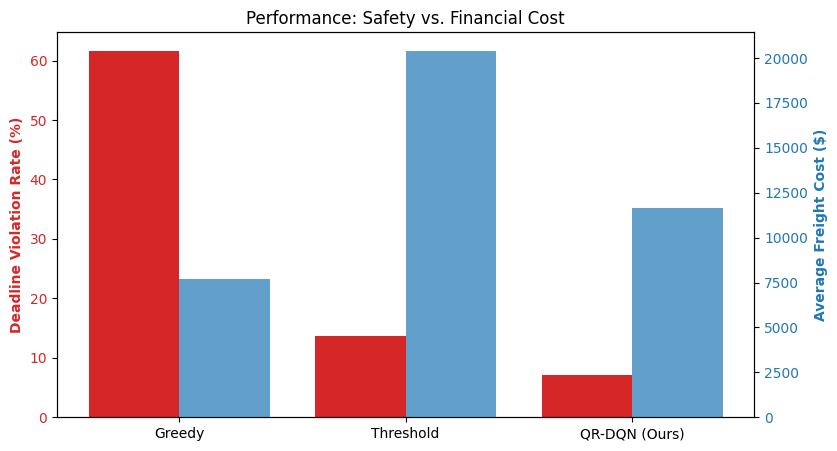

In [1]:
import sys
import os
import torch
import matplotlib.pyplot as plt

# Connect local modules
sys.path.append(os.path.abspath('.'))
from envs.dubai_humanitarian_env import DubaiHumanitarianEnv
from agents.heuristics import GreedyCheapestAgent, StaticThresholdAgent
from agents.qr_dqn_agent import QRDQNAgent
from scripts.evaluate_model import evaluate_agent

env = DubaiHumanitarianEnv()
greedy = GreedyCheapestAgent(env)
threshold = StaticThresholdAgent(env, urgency_threshold=12.0)

# Load the highly-trained agent
rl_agent = QRDQNAgent()
checkpoint = torch.load(
    "results/checkpoints/qr_dqn_model.pth",
    map_location=rl_agent.device,
    weights_only=True,
)
rl_agent.network.load_state_dict(checkpoint.get("model_state_dict", checkpoint))
rl_agent.network.eval()

# Run evaluation (fast-forwarding 500 episodes for demonstration)
print("Evaluating agents...")
greedy_metrics = evaluate_agent(greedy, env, "heuristic", episodes=500, seed=0)
threshold_metrics = evaluate_agent(threshold, env, "heuristic", episodes=500, seed=0)
rl_metrics = evaluate_agent(rl_agent, env, "rl", episodes=500, seed=0)

# Plot inline
labels = ['Greedy', 'Threshold', 'QR-DQN (Ours)']
metrics = [greedy_metrics, threshold_metrics, rl_metrics]
violations = [item["violation_rate"] for item in metrics]
costs = [item["average_cost"] for item in metrics]

fig, ax1 = plt.subplots(figsize=(9, 5))
color = 'tab:red'
ax1.set_ylabel('Deadline Violation Rate (%)', color=color, fontweight='bold')
ax1.bar([x - 0.2 for x in range(3)], violations, width=0.4, color=color, label='Violation Rate')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(range(3))
ax1.set_xticklabels(labels)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Average Freight Cost ($)', color=color, fontweight='bold')
ax2.bar([x + 0.2 for x in range(3)], costs, width=0.4, color=color, alpha=0.7, label='Cost')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Performance: Safety vs. Financial Cost')
plt.show()

### 4. Live Episode Trace
To prove the agent adapts dynamically to local states, we force a high-risk OOD (Out-Of-Distribution) scenario: a critical Tier 1 cargo with a tight 10-day deadline and a 30% shock probability.

In [2]:
from scripts.demo import run_live_demo

# Execute the live human-readable trace
run_live_demo()


DUBAI HUMANITARIAN LIVE DISPATCH DEMO
Cargo: Tier 1 | Deadline: 10.0 days | Disruption Risk: 30.000001907348633%
--------------------------------------------------
Current Location: Dubai Hub
Agent selects: LAND_TO_HUB
Current Location: Regional Checkpoint
Agent selects: CONTINUE_NOMINAL
--------------------------------------------------
Episode Terminated: SUCCESS (On Time)
Total Days Taken: 6.4
